# Laboratory Activity 6 — CNN Architecture Diagram → PyTorch

**Instruction:** Convert the given CNN architecture diagram into a PyTorch CNN architecture.

### Reading the Diagram

The given CNN architecture accepts a single-channel 28 × 28 input image. It consists of four convolutional layers, two max-pooling layers, dropout, and three fully connected layers.

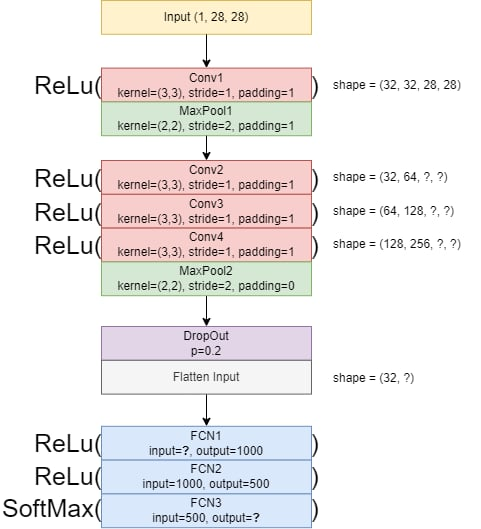

In [1]:
from IPython.display import Image, display
display(Image("assets/lab6.jpg"))

### The architecture can be summarized as follows:

| **Layer**    | **Configuration**                                          |
| ------------ | ---------------------------------------------------------- |
| **Input**    | `1 × 28 × 28`                                              |
| **Conv1**    | `1 → 32`, kernel = `3 × 3`, stride = `1`, padding = `1`    |
| **ReLU**     | Activation                                                 |
| **MaxPool1** | kernel = `2 × 2`, stride = `2`, padding = `1`              |
| **Conv2**    | `32 → 64`, kernel = `3 × 3`, stride = `1`, padding = `1`   |
| **ReLU**     | Activation                                                 |
| **Conv3**    | `64 → 128`, kernel = `3 × 3`, stride = `1`, padding = `1`  |
| **ReLU**     | Activation                                                 |
| **Conv4**    | `128 → 256`, kernel = `3 × 3`, stride = `1`, padding = `1` |
| **ReLU**     | Activation                                                 |
| **MaxPool2** | kernel = `2 × 2`, stride = `2`, padding = `0`              |
| **Dropout**  | `p = 0.2`                                                  |
| **Flatten**  | —                                                          |
| **FCN1**     | `? → 1000`                                                 |
| **ReLU**     | Activation                                                 |
| **FCN2**     | `1000 → 500`                                               |
| **ReLU**     | Activation                                                 |
| **FCN3**     | `500 → 10`                                                 |
| **Softmax**  | 10 output classes                                          |


The convolutional layers progressively increase the number of feature channels from 1 to 256. Meanwhile, the pooling layers reduce the spatial dimensions of the feature maps. After the convolutional portion, the resulting feature maps are flattened and passed through fully connected layers for classification.

## 1. Working Out the `?` Values 
For convolutional and pooling layers, the spatial output dimension can be calculated using:
$$\text{out} = \left\lfloor \frac{\text{in} + 2 \times \text{padding} - \text{kernel}}{\text{stride}} \right\rfloor + 1$$


In [1]:
def conv_out(size, kernel, stride, padding):
    return (size + 2 * padding - kernel) // stride + 1

In [2]:
h = 28

print("Input:                  ", h, "x", h, " channels=1")

h = conv_out(h, kernel=3, stride=1, padding=1)
print("After Conv1  (1->32):   ", h, "x", h, " channels=32")

h = conv_out(h, kernel=2, stride=2, padding=1)
print("After MaxPool1:         ", h, "x", h, " channels=32")

h = conv_out(h, kernel=3, stride=1, padding=1)
print("After Conv2  (32->64):  ", h, "x", h, " channels=64")

h = conv_out(h, kernel=3, stride=1, padding=1)
print("After Conv3  (64->128): ", h, "x", h, " channels=128")

h = conv_out(h, kernel=3, stride=1, padding=1)
print("After Conv4  (128->256):", h, "x", h, " channels=256")

h = conv_out(h, kernel=2, stride=2, padding=0)
print("After MaxPool2:         ", h, "x", h, " channels=256")

flat_dim = 256 * h * h

print("\nFlattened feature size (input to FCN1):", flat_dim)

Input:                   28 x 28  channels=1
After Conv1  (1->32):    28 x 28  channels=32
After MaxPool1:          15 x 15  channels=32
After Conv2  (32->64):   15 x 15  channels=64
After Conv3  (64->128):  15 x 15  channels=128
After Conv4  (128->256): 15 x 15  channels=256
After MaxPool2:          7 x 7  channels=256

Flattened feature size (input to FCN1): 12544


### 1.1 Imports

In [3]:
import torch
import torch.nn as nn

## 2. Define the CNN as an `nn.Module`

In [4]:
class DiagramCNN(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()

        # --- Block 1: Conv1 -> ReLU -> MaxPool1 ---
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=1),
        )

        # --- Block 2: Conv2 -> ReLU ---
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # --- Block 3: Conv3 -> ReLU ---
        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # --- Block 4: Conv4 -> ReLU -> MaxPool2 ---
        self.block4 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),
        )

        # --- Dropout + Flatten ---
        self.dropout = nn.Dropout(p=0.2)
        self.flatten = nn.Flatten()

        # --- Fully connected head: FCN1 -> ReLU -> FCN2 -> ReLU -> FCN3 -> SoftMax ---
        flattened_dim = 256 * 7 * 7   # = 12544, derived above
        self.classifier = nn.Sequential(
            nn.Linear(in_features=flattened_dim, out_features=1000),
            nn.ReLU(),
            nn.Linear(in_features=1000, out_features=500),
            nn.ReLU(),
            nn.Linear(in_features=500, out_features=num_classes),
            nn.Softmax(dim=1),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.dropout(x)
        x = self.flatten(x)
        x = self.classifier(x)
        return x


##  3. Instantiate the Model and Inspect It

In [5]:
model = DiagramCNN(num_classes=10)
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


DiagramCNN(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (block4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=12544, out_features=1000, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1000, out_features=500, bias=True)
    (3): ReLU()
    (4): Linear(in_features=500, out_features=10, bias=True)
    

## 4. Sanity-Check With a Dummy Batch

To verify that the implementation matches the calculated dimensions, a dummy batch of 32 grayscale images with dimensions 28 x 28 is passed through the network.


In [6]:
dummy_input = torch.randn(32, 1, 28, 28)

print("Tensor Shape Verification")
print("-" * 50)

x = dummy_input
print("Input:         ", x.shape)

x = model.block1(x)
print("After Block 1: ", x.shape)

x = model.block2(x)
print("After Block 2: ", x.shape)

x = model.block3(x)
print("After Block 3: ", x.shape)

x = model.block4(x)
print("After Block 4: ", x.shape)

x = model.dropout(x)
x = model.flatten(x)

print("After Flatten: ", x.shape)

x = model.classifier(x)

print("Final Output:  ", x.shape)

Tensor Shape Verification
--------------------------------------------------
Input:          torch.Size([32, 1, 28, 28])
After Block 1:  torch.Size([32, 32, 15, 15])
After Block 2:  torch.Size([32, 64, 15, 15])
After Block 3:  torch.Size([32, 128, 15, 15])
After Block 4:  torch.Size([32, 256, 7, 7])
After Flatten:  torch.Size([32, 12544])
Final Output:   torch.Size([32, 10])


### 4.1 Interpretation

The resulting tensor dimensions match the dimensions calculated from the architecture diagram. In particular, the convolutional and pooling blocks produce a $$(256\times7\times7)$$ feature map, which is flattened into 12,544 features. The final output has dimensions $$(32\times10)$$, representing 10 class scores for each of the 32 input images. The final layer of the diagram contains a Softmax activation. Softmax converts the output scores into values between 0 and 1 whose sum for each sample is approximately 1.

In [7]:
output = model(dummy_input)

print("Final output shape:", output.shape)

print("\nRow sums of final output:")
print(output.sum(dim=1))

Final output shape: torch.Size([32, 10])

Row sums of final output:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


Each row of the output sums to approximately 1.0, confirming that Softmax is normalizing the outputs into a probability distribution across the 10 classes.

### 4.2  Parameter Distribution Across Layers

The number of trainable parameters can be visualized to determine which layers contribute most to the model's size.

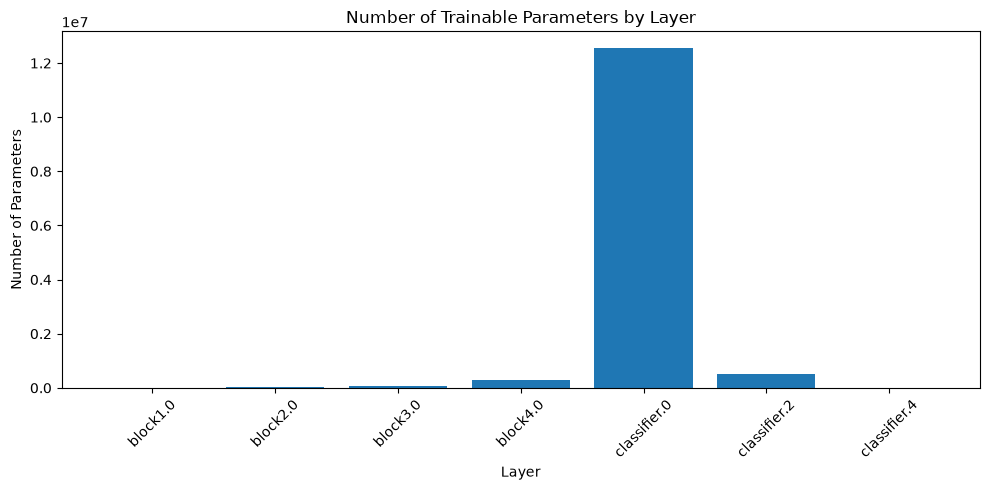

In [8]:
import matplotlib.pyplot as plt

layers = []
parameters = []

for name, layer in model.named_modules():

    if isinstance(layer, (nn.Conv2d, nn.Linear)):

        layers.append(name)

        parameters.append(
            sum(p.numel() for p in layer.parameters())
        )

plt.figure(figsize=(10, 5))

plt.bar(layers, parameters)

plt.title("Number of Trainable Parameters by Layer")
plt.xlabel("Layer")
plt.ylabel("Number of Parameters")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The parameter distribution shows that the fully connected portion of the network contains substantially more parameters than the convolutional layers. FCN1 contributes the largest number of parameters because its 12,544 input features are connected to 1,000 neurons. This demonstrates how flattening high-dimensional feature maps before a fully connected layer can significantly increase the number of trainable parameters.

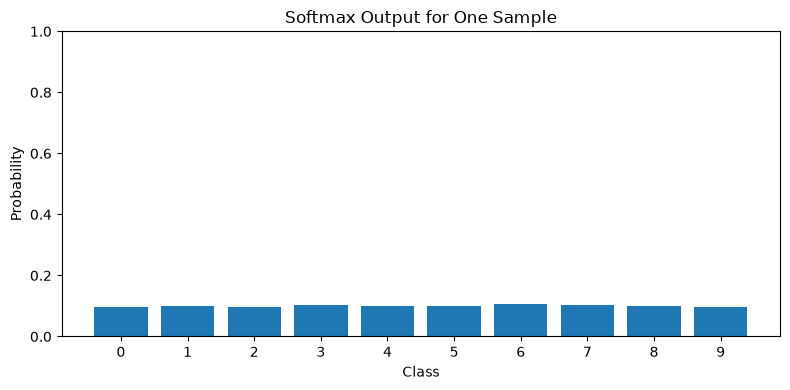

In [9]:
sample_probabilities = output[0].detach().numpy()

plt.figure(figsize=(8, 4))

plt.bar(
    range(10),
    sample_probabilities
)

plt.title("Softmax Output for One Sample")
plt.xlabel("Class")
plt.ylabel("Probability")

plt.xticks(range(10))
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

The bar chart represents the Softmax probabilities assigned to the 10 output classes for one input sample. The probabilities sum to approximately 1. The visualization is used only to demonstrate the behavior of the Softmax layer.

### 4.3 Architecture Summary

| Stage   | Input         | Operation                 | Output        |
| ------- | ------------- | ------------------------- | ------------- |
| Input   | —             | Grayscale image           | 1 × 28 × 28   |
| Conv1   | 1 × 28 × 28   | Conv2D, 32 filters        | 32 × 28 × 28  |
| Pool1   | 32 × 28 × 28  | MaxPool                   | 32 × 15 × 15  |
| Conv2   | 32 × 15 × 15  | Conv2D, 64 filters        | 64 × 15 × 15  |
| Conv3   | 64 × 15 × 15  | Conv2D, 128 filters       | 128 × 15 × 15 |
| Conv4   | 128 × 15 × 15 | Conv2D, 256 filters       | 256 × 15 × 15 |
| Pool2   | 256 × 15 × 15 | MaxPool                   | 256 × 7 × 7   |
| Flatten | 256 × 7 × 7   | Flatten                   | 12,544        |
| FCN1    | 12,544        | Linear                    | 1,000         |
| FCN2    | 1,000         | Linear                    | 500           |
| FCN3    | 500           | Linear                    | 10            |
| Softmax | 10            | Probability normalization | 10            |
